In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("streaming_music.json")

display(df.head())
print(df.columns)

,track_id,track_name,genre,minutes,popularity,release_year,streams_millions,city,latitude,longitude
0,1,Track 001,Pop,3.04,65,2023,54.3,New York,40.7128,-74.0060
1,2,Track 002,Hip-hop,4.98,83,2014,56.7,Chicago,41.8781,-87.6298
2,3,Track 003,Rock,3.32,86,2024,201.6,Miami,25.7617,-80.1918
3,4,Track 004,Electronic,4.00,68,2012,151.7,Miami,25.7617,-80.1918
4,5,Track 005,Jazz,6.22,63,2022,124.6,Seattle,47.6062,-122.3321


Index(['track_id', 'track_name', 'genre', 'minutes', 'popularity',
       'release_year', 'streams_millions', 'city', 'latitude', 'longitude'],
      dtype='str')


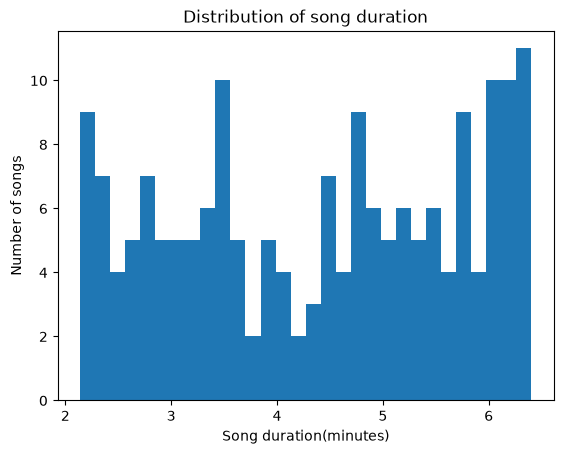

In [2]:
plt.hist(df["minutes"], bins=30)
plt.title("Distribution of song duration")
plt.xlabel("Song duration(minutes)")
plt.ylabel("Number of songs")
plt.show()

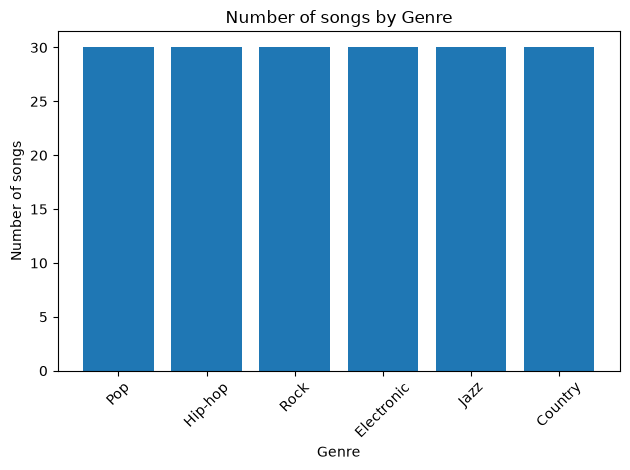

In [3]:
genre_counts = df["genre"].value_counts()

plt.bar( 
    genre_counts.index,
    genre_counts.values
)

plt.title("Number of songs by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of songs")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

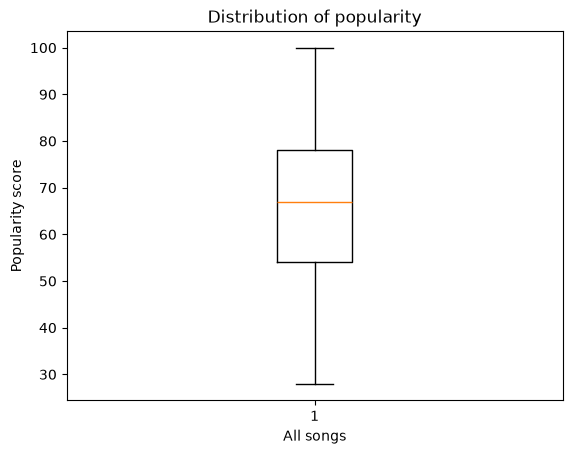

In [4]:
plt.boxplot(df["popularity"])
plt.title("Distribution of popularity")
plt.xlabel("All songs")
plt.ylabel("Popularity score")
plt.show()

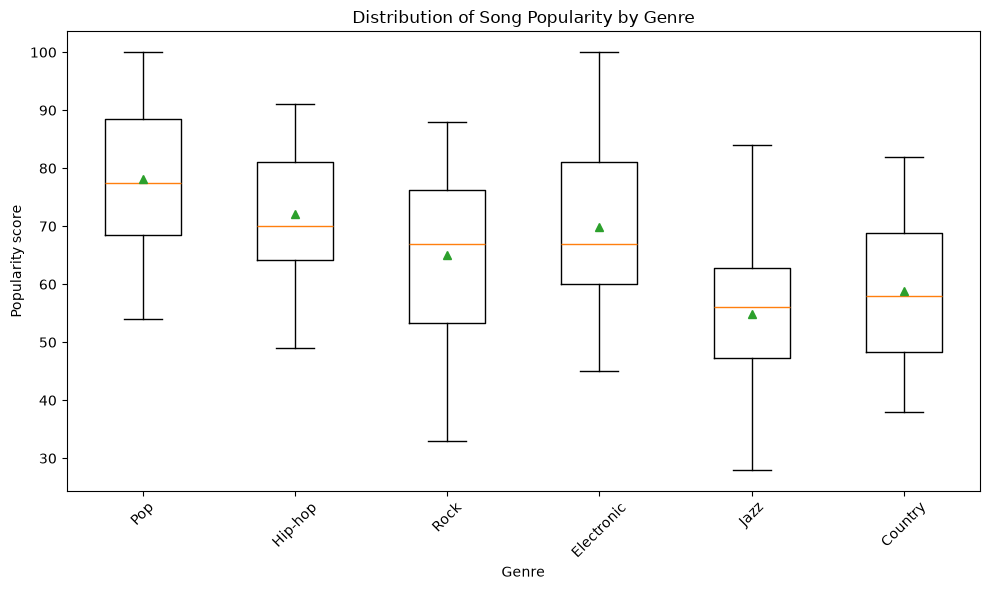

In [5]:
genres = df["genre"].unique()

popularity_genre = [
    df.loc[df["genre"] == genre, "popularity"]
    for genre in genres
]

plt.figure(figsize=(10, 6))
plt.boxplot(popularity_genre, tick_labels=genres, showmeans=True)

plt.title("Distribution of Song Popularity by Genre")
plt.xlabel("Genre")
plt.ylabel("Popularity score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

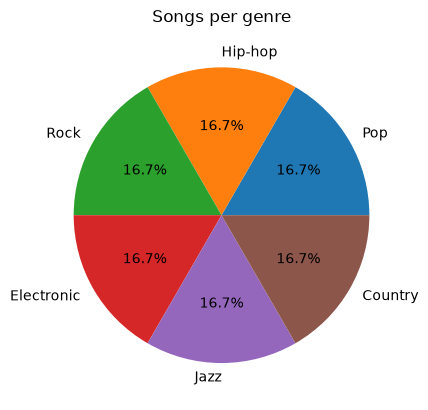

In [22]:
genre_counts = df["genre"].value_counts()

plt.pie(
    genre_counts.values,
    labels=genre_counts.index,
    autopct = "%1.1f%%"
)
plt.title("Songs per genre")
plt.show()

In [ ]:
plt.scatter(
    df["minutes"],
    df["popularity"]
)

plt.title("Song duration vs popularity")
plt.xlabel("song duration - minutes")
plt.ylabel("popularity score")
plt.show()

In [ ]:
plt.scatter(
    df["release_year"],
    df["streams_millions"]
)
plt.title("Release year vs streaming numbers")
plt.xlabel("Release Year")
plt.ylabel("Streams (millions)")
plt.show()

In [ ]:
import plotly.express as px

city_streams = df.groupby(
    ["city", "latitude", "longitude"],
    as_index=False
)["streams_millions"].sum()

fig = px.scatter_geo(
    city_streams, 
    lat="latitude",
    lon="longitude",
    size="streams_millions",
    hover_name="city",
    scope="usa",
    title="Music streams by city"
)
fig.show()

In [ ]:
states = pd.DataFrame({
    "state":["OH","CA","NY","TX","FL","WA"],
    "streams":[50,90,85,70,60,45]
})

fig = px.choropleth(
    states,
    locations="state",
    locationmode="USA-states",
    color="streams",
    scope="usa",
    title="Music streams by state"
)
fig.show()

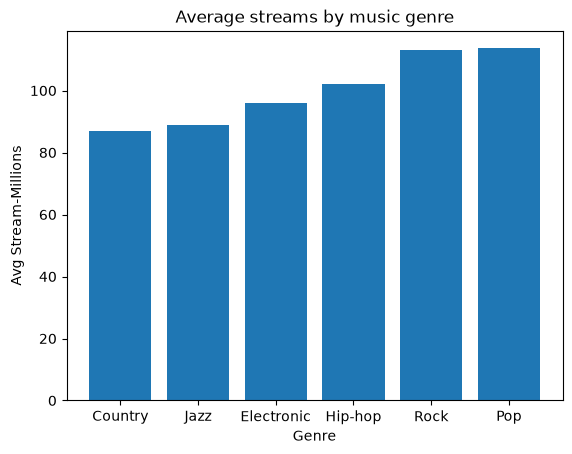

<Figure size 900x500 with 0 Axes>

In [9]:
genre_streams = (
    df.groupby("genre")["streams_millions"]
    .mean()
    .sort_values()
)


plt.bar(genre_streams.index, genre_streams.values)

plt.title("Average streams by music genre")
plt.xlabel("Genre")
plt.ylabel("Avg Stream-Millions")
plt.figure(figsize=(9,5))

plt.show()

Text(0.0, 1.0, 'Which music genre receives the most streams?')

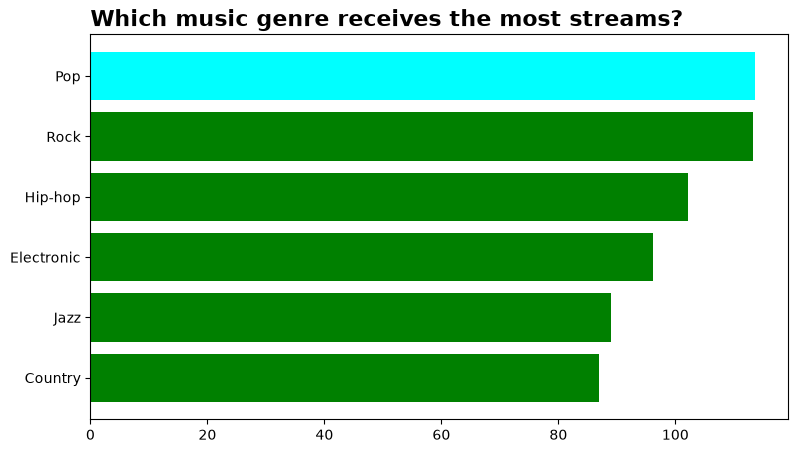

In [14]:
plt.figure(figsize=(9,5))

colors = [
    "aqua" if genre == genre_streams.idxmax()
    else "green"
    for genre in genre_streams.index
]

plt.barh(
    genre_streams.index,
    genre_streams.values,
    color=colors
)

plt.title(
    "Which music genre receives the most streams?",
    fontsize=16,
    fontweight="bold",
    loc="left"
)
    

In [15]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


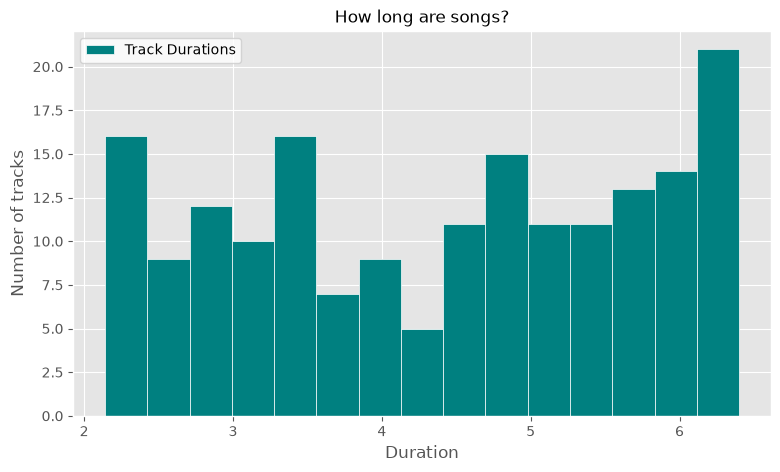

In [17]:
with plt.style.context("ggplot"):
    plt.figure(figsize=(9,5))

    plt.hist(
        df["minutes"],
        bins=15,
        color="teal",
        edgecolor="white",
        label="Track Durations"
    )

plt.title("How long are songs?")
plt.xlabel("Duration")
plt.ylabel("Number of tracks")
plt.legend()
plt.show()

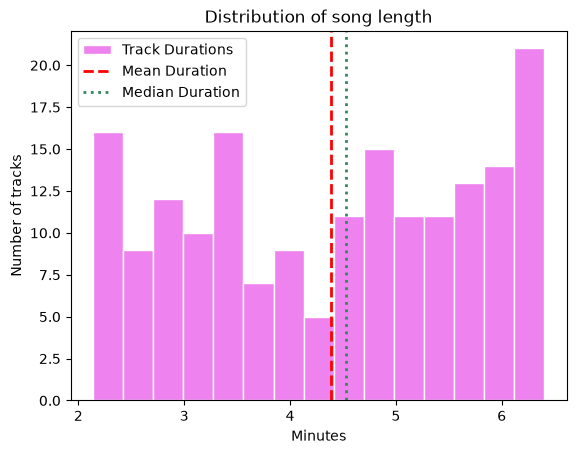

In [21]:
plt.hist(
    df["minutes"],
    bins=15,
    color="violet",
    edgecolor="white",
    label="Track Durations"
)

plt.axvline(
    df["minutes"].mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mean Duration"
)

plt.axvline(
    df["minutes"].median(),
    color="seagreen",
    linestyle=":",
    linewidth=2,
    label="Median Duration"
)

plt.title("Distribution of song length")
plt.xlabel("Minutes")
plt.ylabel("Number of tracks")
plt.legend()
plt.show()


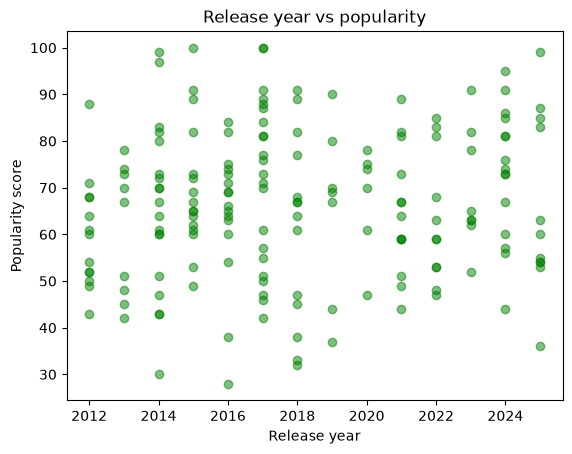

In [25]:
plt.scatter(
    df["release_year"],
    df["popularity"],
    alpha=0.5,
    color="green"
)

plt.title("Release year vs popularity")
plt.xlabel("Release year")
plt.ylabel("Popularity score")
plt.show()

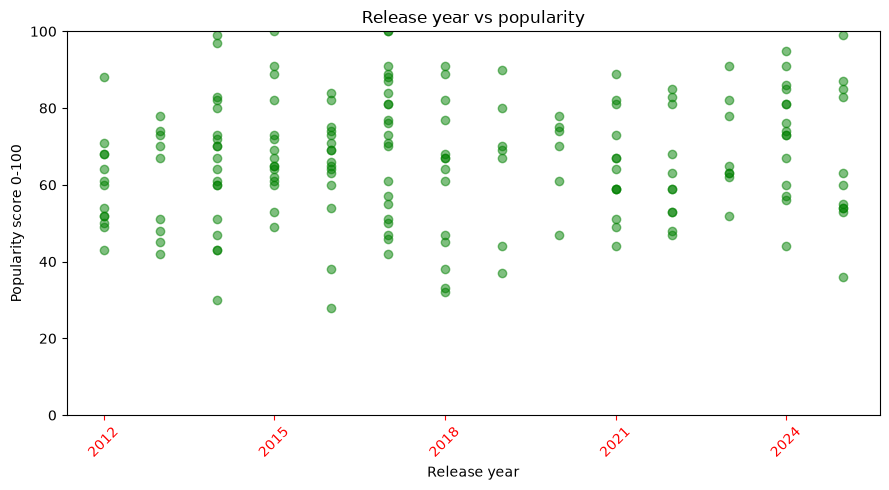

In [33]:
fig, ax = plt.subplots(figsize=(9,5))

ax.scatter(
    df["release_year"],
    df["popularity"],
    alpha=0.5,
    color="green"
)

ax.set_title("Release year vs popularity")
ax.set_xlabel("Release year")
ax.set_ylabel("Popularity score 0-100")

ax.set_xticks([2012, 2015, 2018, 2021, 2024])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_ylim(0,100)

ax.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=10,
    colors="red"
)
plt.tight_layout()
plt.show()

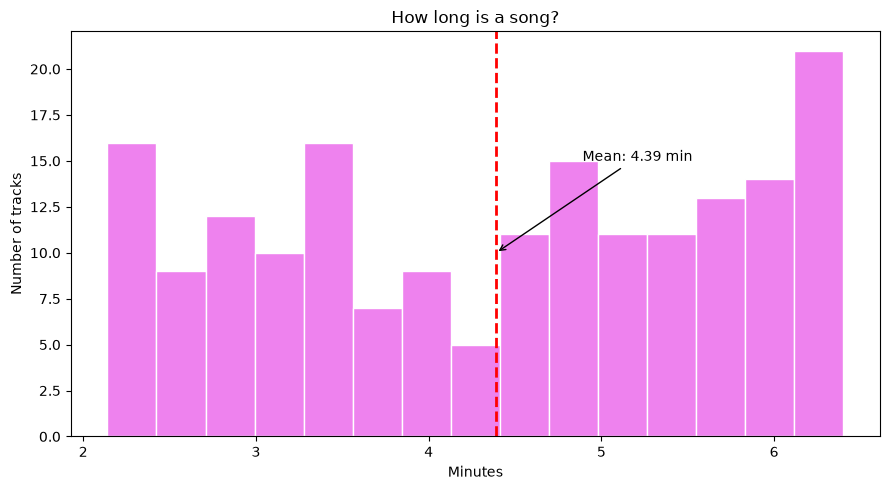

In [31]:
fig, ax = plt.subplots(figsize=(9,5))

ax.hist(
    df["minutes"],
    bins=15,
    color="violet",
    edgecolor="white",
)

mean_minutes = df["minutes"].mean()


ax.axvline(
    mean_minutes,
    color="red",
    linestyle="--",
    linewidth=2,
)

ax.annotate(
    f"Mean: {mean_minutes:.2f} min",
    xy=(mean_minutes, 10),
    xytext=(mean_minutes + 0.5, 15),
    arrowprops={"arrowstyle": "->"}
)

ax.set_title("How long is a song?")
ax.set_xlabel("Minutes")
ax.set_ylabel("Number of tracks")

plt.tight_layout()
plt.show()
